## Figure 4. Performance and thresholding of the NMWI. 
**(a)** Distribution of classification performance across individual studies under LOSO CV. Bars represent the number of healthy (blue) and non-healthy (red) samples per cohort, while points indicate cohort-specific accuracy (green line). The dashed line denotes the cross-cohort mean LOSO accuracy (73.0%). **(b)** Receiver operating characteristic curves for classification performance in distinguishing healthy and non-healthy phenotypes under resubstitution (AUROC = 0.83), 10×10 CV (AUROC = 0.81), and LOSO CV (AUROC = 0.76). **(c)** LODO analysis of generalizability across disease conditions. **(d)** Increasing the magnitude cutoff improves classification performance, while reducing the proportion of samples retained. Balanced accuracies from 10×10 CV are shown in blue (±SD shading), with the percentage of retained samples in yellow (±SD shading). Classification accuracies at selected magnitude cutoffs (0, 0.5, 1) under **(e)** 10×10 CV and **(f)** resubstitution. Bars show group performance; green lines indicate retained samples.


In [1]:
from pathlib import Path
import os
import pandas as pd
import numpy as np
import warnings, sys, runpy
import matplotlib
# matplotlib.use("cairo")
import matplotlib.pyplot as plt

import seaborn as sns
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import balanced_accuracy_score, recall_score, confusion_matrix
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator

warnings.filterwarnings("ignore")
warnings.filterwarnings("ignore", message="pkg_resources is deprecated as an API")

project_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if p.name == "NMWI")
os.chdir(project_root)

In [2]:
%matplotlib inline
# METADATA LOADING
vars_dict = runpy.run_path("Codes/Auxiliary_files/Generate_data_index.py")
globals().update(vars_dict)
X_new = X.copy()

Found 27 genus tables in index
Number of samples: 1654, and number of taxa: 184
Number of unique studies: 27

Sample ID per Category:
Category  n_Sample ID
    case         1065
 control          589


- X: DataFrame (rows=samples, cols=taxonomy), index includes bioproject/sample_id RELATIVE ABUNDANCE
- y: Series/array-like of True/False (same index as X), True (1) =control, False=case

In [3]:
%run -i Codes/Auxiliary_files/NMWI.py # Run model

Positive coefs: 14
Negative coefs: 10
zero coefs: 160


---
### Figure 4a


**Note:** 
Nested LOSO cross-validation is computationally intensive and was run separately using `Codes/Auxiliary_files/nested_LOSO.py`. The precomputed fold-level results are loaded below for downstream analysis and visualization. To reproduce the analysis:

```bash
python Codes/Auxiliary_files/nested_LOSO.py
```

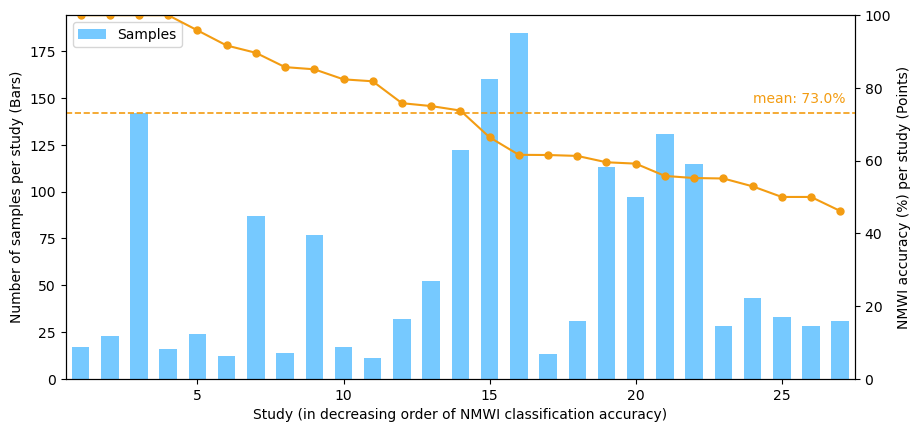

In [4]:
# Load precomputed LOSO coefficients
loso_df = pd.read_csv("Data/Output/nested_loso_summary.tsv", sep="\t", index_col="BioProject")
loso_df = loso_df[loso_df["Row"] == "FOLD"]
plot_df = loso_df.sort_values("Accuracy", ascending=False).reset_index(drop=True)
plot_df["Study_idx"] = np.arange(1, len(plot_df) + 1)

acc_pct = plot_df["Accuracy"] * 100
mean_acc = acc_pct.mean()

# Dimensions
width_pt = 242; height_pt = 115
width_in = width_pt /26 ; height_in = height_pt / 26

fig, ax1 = plt.subplots(figsize=(width_in, height_in))
width = 0.6

# Stacked bars: positives + negatives per held-out study
ax1.bar(
    plot_df["Study_idx"], plot_df["n_test"],
    width=width, color="#76c9ff", edgecolor="none", label="Samples"
)

ax1.set_xlabel("Study (in decreasing order of NMWI classification accuracy)")
ax1.set_ylabel("Number of samples per study (Bars)")
ax1.set_xlim(0.5, len(plot_df) + 0.5)

ax1.legend(loc="upper left", frameon=True)

# Line: accuracy per study
ax2 = ax1.twinx()
ax2.plot(
    plot_df["Study_idx"], acc_pct,
    "o-", linewidth=1.5, markersize=5, color="#f39c12"
)
ax2.set_ylabel("NMWI accuracy (%) per study (Points)")
ax2.set_ylim(0, 100)

# Mean accuracy reference line
ax2.axhline(mean_acc, linestyle="--", linewidth=1.2, color="#f39c12")
ax2.text(
    len(plot_df) - 3, mean_acc + 2,
    f"mean: {mean_acc:.1f}%",
    color="#f39c12", ha="left", va="bottom"
)

plt.tight_layout()
plt.show()

---
### Figure 4b

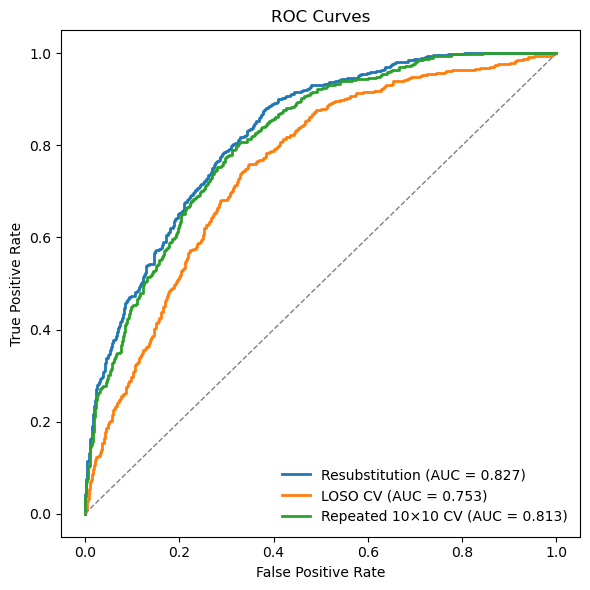

Resubstitution AUC: 0.8268
LOSO CV AUC: 0.7527
Repeated 10x10 CV AUC: 0.8128


In [6]:
# Resubstitution
y_full = np.asarray(y).ravel()
scores_full = NMWI.decision_function(X_new)
full_auc = roc_auc_score(y_full, scores_full)
fpr_full, tpr_full, _ = roc_curve(y_full, scores_full)

# LOSO
loso = pd.read_csv("Data/Output/nested_loso_oof_predictions.tsv", sep="\t")
y_loso, scores_loso = loso["True_label"].astype(int), loso["Prediction_score"]
loso_auc = roc_auc_score(y_loso, scores_loso)
fpr_loso, tpr_loso, _ = roc_curve(y_loso, scores_loso)

# Repeated 10x10 CV: average 10 OOF scores per sample
cv = pd.read_csv("Data/Output/10x10_oof_predictions.csv")
cv_mean = cv.groupby("row_position").agg(
    true_label=("true_label", "first"),
    decision_score=("decision_score", "mean")
).sort_index()

y_cv, scores_cv = cv_mean["true_label"], cv_mean["decision_score"]
cv_auc = roc_auc_score(y_cv, scores_cv)
fpr_cv, tpr_cv, _ = roc_curve(y_cv, scores_cv)

# Plot
plt.figure(figsize=(6, 6))
plt.plot(fpr_full, tpr_full, lw=2, label=f"Resubstitution (AUC = {full_auc:.3f})")
plt.plot(fpr_loso, tpr_loso, lw=2, label=f"LOSO CV (AUC = {loso_auc:.3f})")
plt.plot(fpr_cv, tpr_cv, lw=2, label=f"Repeated 10×10 CV (AUC = {cv_auc:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", lw=1)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

print(f"Resubstitution AUC: {full_auc:.4f}")
print(f"LOSO CV AUC: {loso_auc:.4f}")
print(f"Repeated 10x10 CV AUC: {cv_auc:.4f}")

---
### Figure 4c

Total LODO folds (including healthy): 8
  Disease  n_test  pos_test  neg_test        BA
5     GPA      68       589        68  0.308824
6      RA      21       589        21  0.333333
3     CRS     652       589       652  0.664110
4  CRS-AS      34       589        34  0.705882
0      AR     137       589       137  0.708029
1  Asthma     123       589       123  0.821138
2      CF      30       589        30  0.933333
LODO mean balanced accuracy: 0.6392357695614095


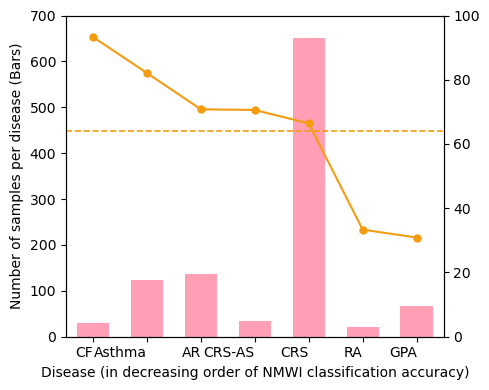

In [7]:
## LODO
y_arr = y.values.ravel()
temp_t = training_set.reset_index()
temp_t = temp_t.set_index(['BioProject Number', 'Disease', 'Sample ID'])
X_lodo = temp_t[[c for c in temp_t.columns if c.startswith("d__")]]

disease_ids = np.array(X_lodo.index.get_level_values("Disease"))

lodo = LeaveOneGroupOut()
lodo_splits = list(lodo.split(X_lodo, y_arr, groups=disease_ids))
print("Total LODO folds (including healthy):", len(lodo_splits))

fold_bas = []
lodo_loop = []

for train_idx, test_idx in lodo_splits:
    disease_te = pd.Index(disease_ids[test_idx]).unique().tolist()[0]

    if str(disease_te) == "Healthy":
        continue

    X_tr = X_lodo.iloc[train_idx]
    y_tr = y_arr[train_idx]
    X_te = X_lodo.iloc[test_idx]
    y_te = y_arr[test_idx]

    disease_train = disease_ids[train_idx]
    disease_train_ser = pd.Series(disease_train)

    lodo_model = LogisticRegression(**final_params)
    lodo_model.fit(X_tr, y_tr)

    y_hat = lodo_model.predict(X_te)
    ba = balanced_accuracy_score(y_te, y_hat) 
    fold_bas.append(ba)

    pos_test = int(y_tr.sum())
    neg_test = int((~pd.Series(y_te.astype(bool))).sum())

    lodo_loop.append({
        "Disease": disease_te,
        "n_test": len(test_idx),
        "pos_test": pos_test,
        "neg_test": neg_test,
        "BA": ba 
    })

lodo_df = pd.DataFrame(lodo_loop).sort_values("BA")
print(lodo_df)

mean_cv_ba = float(np.mean(fold_bas)) if fold_bas else np.nan
print("LODO mean balanced accuracy:", mean_cv_ba)

plot_df = lodo_df.sort_values("BA", ascending=False).reset_index(drop=True)
plot_df["Disease_idx"] = np.arange(1, len(plot_df) + 1)

acc_pct = plot_df["BA"] * 100
mean_acc = acc_pct.mean()

fig, ax1 = plt.subplots(figsize=(5, 4))

ax1.bar(
    plot_df["Disease_idx"],
    plot_df["neg_test"],              # non-healthy samples in test fold
    width=width,
    # bottom=plot_df["pos_test"],       # <<-- stack
    color="#ff9fb5",
    edgecolor="none",
    label="Non-healthy samples"
)

ax1.set_xlabel("Disease (in decreasing order of NMWI classification accuracy)")
ax1.set_ylabel("Number of samples per disease (Bars)")
ax1.set_xlim(0.5, len(plot_df) + 0.5)
ax1.set_ylim(0,700)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax1.set_xticks(plot_df["Disease_idx"])
ax1.set_xticklabels(plot_df["Disease"], ha="right")

ax2 = ax1.twinx()
ax2.plot(
    plot_df["Disease_idx"],
    acc_pct,
    "o-",
    linewidth=1.5,
    markersize=5,
    color="#f39c12"
)

ax2.axhline(mean_acc, linestyle="--", linewidth=1.2, color="#f39c12")
ax2.set_ylim(0, 100)
plt.tight_layout()

plt.show()

---
### Figure 4d

,cutoff,samples_retained,samples_retained_sd,bal_acc,bal_acc_sd,recall,tnr
0,0.0,1.000000,0.000000,0.734276,0.037957,0.775210,0.693342
1,0.1,0.932698,0.020283,0.749915,0.037836,0.793713,0.706117
2,0.2,0.860582,0.024001,0.765270,0.037625,0.815757,0.714784
3,0.3,0.779758,0.030849,0.787055,0.040237,0.847512,0.726599
4,0.4,0.709739,0.030388,0.800367,0.037542,0.868894,0.731841
5,0.5,0.642266,0.030302,0.814951,0.038559,0.881861,0.748041
6,0.6,0.567964,0.032718,0.834874,0.042228,0.887482,0.782267
7,0.7,0.487376,0.037177,0.852134,0.045838,0.886009,0.818258
8,0.8,0.410410,0.037196,0.868157,0.048852,0.887209,0.849105
9,0.9,0.355142,0.035020,0.895177,0.046798,0.903133,0.887221


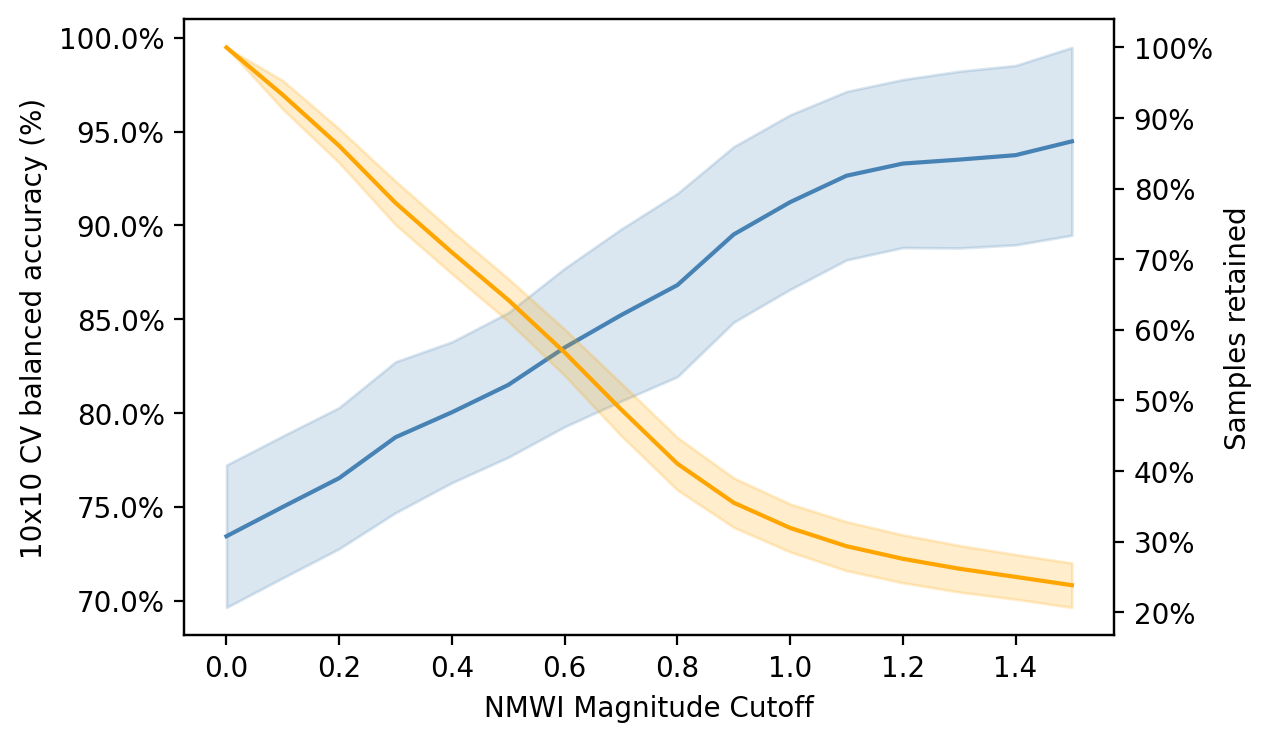

In [8]:
cutoff = pd.read_csv("Data/Output/10x10_cutoff_fold_results.csv")

df_cutoff = cutoff.groupby("cutoff").agg(
    samples_retained=("samples_retained", "mean"),
    samples_retained_sd=("samples_retained", lambda x: x.std(ddof=0)),
    bal_acc=("bal_acc", "mean"),
    bal_acc_sd=("bal_acc", lambda x: x.std(ddof=0)),
    recall=("recall", "mean"),
    tnr=("tnr", "mean")
).reset_index()

display(df_cutoff)

fig, ax1 = plt.subplots(figsize=(6, 4), dpi=200)
ax2 = ax1.twinx()

x = df_cutoff["cutoff"]
bal, bal_sd = df_cutoff["bal_acc"], df_cutoff["bal_acc_sd"]
ret, ret_sd = df_cutoff["samples_retained"], df_cutoff["samples_retained_sd"]

ax1.plot(x, bal, color="steelblue")
ax1.fill_between(x, bal-bal_sd, bal+bal_sd, color="steelblue", alpha=0.2)

ax2.plot(x, ret, color="orange")
ax2.fill_between(x, ret-ret_sd, ret+ret_sd, color="orange", alpha=0.2)

ax1.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))

ax1.set_ylabel("10x10 CV balanced accuracy (%)", fontsize=10)
ax2.set_ylabel("Samples retained", fontsize=10)
ax1.set_xlabel("NMWI Magnitude Cutoff", fontsize=10)

plt.show()

---
### Figure 4e

    cutoff  samples_retained  samples_retained_sd   bal_acc  bal_acc_sd  \
0      0.0          1.000000             0.000000  0.734276    0.037957   
5      0.5          0.642266             0.030302  0.814951    0.038559   
10     1.0          0.319415             0.033946  0.912378    0.046528   

      recall       tnr  
0   0.775210  0.693342  
5   0.881861  0.748041  
10  0.909988  0.914768  


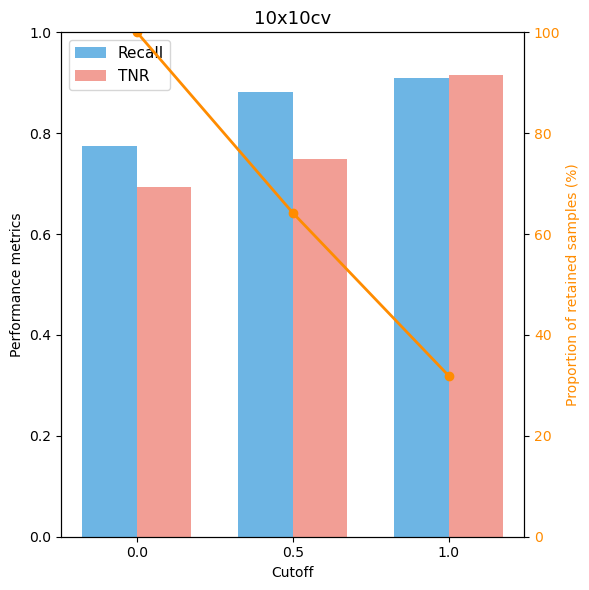

In [9]:
def plot_cutoff_summary(df, title="LOSO", cutoffs=(0, 0.5, 1)):
    df = df.copy()
    df["cutoff"] = pd.to_numeric(df["cutoff"], errors="coerce")
    d = df[df["cutoff"].isin(cutoffs)].sort_values("cutoff")

    print(d)

    x, w = np.arange(len(d)), 0.35
    fig, ax1 = plt.subplots(figsize=(6, 6))

    ax1.bar(x-w/2, d["recall"], w, label="Recall", color="#5DADE2", alpha=0.9)
    ax1.bar(x+w/2, d["tnr"], w, label="TNR", color="#F1948A", alpha=0.9)
    ax1.set(xlabel="Cutoff", ylabel="Performance metrics", ylim=(0, 1))
    ax1.set_xticks(x, d["cutoff"])
    ax1.legend(loc="upper left", fontsize=11)

    ax2 = ax1.twinx()
    ax2.plot(x, d["samples_retained"]*100, "o-", color="darkorange", linewidth=2)
    ax2.set(ylabel="Proportion of retained samples (%)", ylim=(0, 100))
    ax2.tick_params(axis="y", labelcolor="darkorange")
    ax2.yaxis.label.set_color("darkorange")

    plt.title(title, fontsize=13)
    plt.tight_layout()
    plt.show()

plot_cutoff_summary(df_cutoff, title="10x10cv")

### Figure 4f

,cutoff,samples_retained,samples retained sd,bal_acc,bal_acc sd,recall,tnr
0,0.0,1.000000,0.0,0.743743,0.0,0.786078,0.701408
1,0.1,0.940145,0.0,0.757540,0.0,0.803636,0.711443
2,0.2,0.864571,0.0,0.778385,0.0,0.832335,0.724435
3,0.3,0.780532,0.0,0.803917,0.0,0.876652,0.731183
4,0.4,0.714027,0.0,0.812755,0.0,0.887290,0.738220
5,0.5,0.656590,0.0,0.822756,0.0,0.892670,0.752841
6,0.6,0.579202,0.0,0.844080,0.0,0.899110,0.789050
7,0.7,0.509674,0.0,0.862822,0.0,0.892617,0.833028
8,0.8,0.419589,0.0,0.886861,0.0,0.902542,0.871179
9,0.9,0.362757,0.0,0.914377,0.0,0.926316,0.902439


    cutoff  samples_retained  samples retained sd   bal_acc  bal_acc sd  \
0      0.0          1.000000                  0.0  0.743743         0.0   
5      0.5          0.656590                  0.0  0.822756         0.0   
10     1.0          0.326481                  0.0  0.932606         0.0   

      recall       tnr  
0   0.786078  0.701408  
5   0.892670  0.752841  
10  0.935673  0.929539  


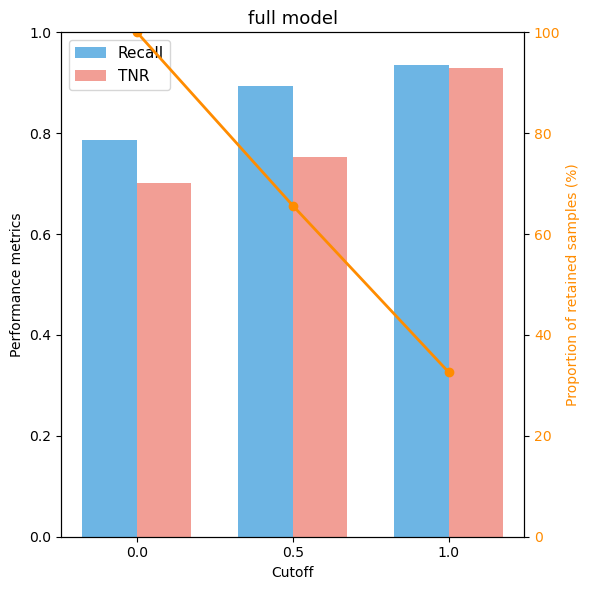

In [10]:
### Full model
interval = 0.1
max_cutoff = 1.5
cutoffs = np.arange(0, max_cutoff + interval, interval)

y_arr = y.values.ravel()
y_train_pred = NMWI.predict(X_new)
scores_all = NMWI.decision_function(X_new)
train_bal_acc = balanced_accuracy_score(y_arr, y_train_pred)

coef = NMWI.coef_.flatten()
feature_names = X_new.columns

coefficients = pd.DataFrame(coef, index=feature_names, columns=["Coefficient"])
sorted_coefficients = coefficients.sort_values("Coefficient", ascending=False)
NMWI_coefs = sorted_coefficients[
    (sorted_coefficients["Coefficient"] > 0) | (sorted_coefficients["Coefficient"] < 0)
]
NMWI_coefs.reset_index().to_csv("Data/Output/NMWI_coefficients.csv", index=False)

num_pos = (sorted_coefficients["Coefficient"] > 0).sum()
num_neg = (sorted_coefficients["Coefficient"] < 0).sum()
num_zero = (sorted_coefficients["Coefficient"] == 0).sum()
num_coef = len(sorted_coefficients)

results_full = {
    c: {"bal_acc": [], "recall": [], "tnr": [], "samples_retained": []}
    for c in cutoffs
}

for c in cutoffs:
    keep = np.abs(scores_all) >= c
    if not np.any(keep):
        continue

    X_keep = X_new.iloc[keep]
    y_keep = y_arr[keep]
    y_pred = NMWI.predict(X_keep)

    ba = balanced_accuracy_score(y_keep, y_pred)
    rec = recall_score(y_keep, y_pred, zero_division=0)

    tn, fp, fn, tp = confusion_matrix(y_keep, y_pred, labels=[0, 1]).ravel()
    tnr = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    results_full[c]["bal_acc"].append(ba)
    results_full[c]["recall"].append(rec)
    results_full[c]["tnr"].append(tnr)
    results_full[c]["samples_retained"].append(keep.mean())

df_cutoff_full = pd.DataFrame([
    {
        "cutoff": c,
        "samples_retained": np.nanmean(results_full[c]["samples_retained"]),
        "samples retained sd": np.nanstd(results_full[c]["samples_retained"]),
        "bal_acc": np.nanmean(results_full[c]["bal_acc"]),
        "bal_acc sd": np.nanstd(results_full[c]["bal_acc"]),
        "recall": np.nanmean(results_full[c]["recall"]),
        "tnr": np.nanmean(results_full[c]["tnr"]),
    }
    for c in cutoffs
])

display(df_cutoff_full)

plot_cutoff_summary(df_cutoff_full, title="full model")
